# Auditoría fotométrica del lote U1

Esta libreta recorre los cinco ejercicios de la práctica sobre las imágenes de `data/`.
Todas las operaciones de realce se aplican sobre el canal Y de YCrCb; las lecturas se
hacen con OpenCV, que devuelve BGR, y esa es la convención interna que se mantiene en
todo el código. Las cifras que aparecen en la memoria salen de los CSV que se generan
aquí.

La semilla queda fijada al principio aunque el flujo sea determinista. Las rutas se
resuelven subiendo desde el directorio de ejecución hasta la carpeta que contiene
`data/` y `codigo/`, de modo que la libreta funciona tanto desde la raíz del proyecto
como desde `codigo/`.

In [1]:
import hashlib
import random
import time
from pathlib import Path

import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage
from IPython.display import display

SEMILLA = 42
np.random.seed(SEMILLA)
random.seed(SEMILLA)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.facecolor": "white",
})


def encontrar_entrega():
    """Localiza la carpeta de entrega desde la raíz o desde codigo/."""
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data").is_dir() and (p / "codigo").is_dir():
            return p
        if (p / "U1_Practica_Hernandez_Ismael" / "data").is_dir():
            return p / "U1_Practica_Hernandez_Ismael"
    raise RuntimeError("No encuentro la carpeta de entrega con data/ y codigo/.")


ENTREGA = encontrar_entrega()
DATA = ENTREGA / "data"
OUT = ENTREGA / "outputs"
MEM = ENTREGA / "memoria"
OUT.mkdir(parents=True, exist_ok=True)
MEM.mkdir(parents=True, exist_ok=True)

HASHES = {
    "IMG_01.jpg": "b76f9fc7be5232cfed6288246fd6dd2b8b95f9082cf38bfc4817965c800e9bf6",
    "IMG_02.jpg": "9d560d957e90bbfaa78b2cae39cf0a5be364cdaedd595ed2a616e9cee4721f0a",
    "IMG_03.jpg": "02031281b21e920ee70eca48d89602486d46c477b2231813962dceb07056d74a",
    "IMG_04.jpg": "922e33cedca7246af596d906fbc01a360aad5bd7bb55c88977aabf71c1d77522",
    "IMG_05.jpg": "bfbaf6828607d9b94fb54056877497ac32926aa75c09de4abd61bc05ba24e2a7",
}
for nombre, esperado in HASHES.items():
    ruta = DATA / nombre
    actual = hashlib.sha256(ruta.read_bytes()).hexdigest()
    if actual != esperado:
        raise RuntimeError(f"El original {nombre} no coincide con el hash de partida.")

imagenes = sorted(DATA.glob("IMG_*.jpg"))
assert len(imagenes) == 5, "Deben estar las cinco imágenes originales."
print("Entrega:", ENTREGA.name)
print("Imágenes verificadas:", ", ".join(p.name for p in imagenes))


def miniatura(img_bgr, ancho=620):
    """Reduce una imagen para visualizarla sin tocar el cálculo."""
    h, w = img_bgr.shape[:2]
    if w <= ancho:
        return img_bgr
    return cv2.resize(img_bgr, (ancho, int(h * ancho / w)), interpolation=cv2.INTER_AREA)

Entrega: U1_Practica_Hernandez_Ismael
Imágenes verificadas: IMG_01.jpg, IMG_02.jpg, IMG_03.jpg, IMG_04.jpg, IMG_05.jpg


## Ejercicio 1. Medir antes de tocar

Uso el canal Y de YCrCb y no la media de R, G y B. Y pondera los tres canales como la
luminancia perceptual, mientras que la media aritmética da el mismo peso al azul que al
verde. Además, al tocar solo Y conservo Cr y Cb, así que el color de la escena no se
altera por el simple hecho de cambiar el contraste. V de HSV es `max(R,G,B)` y mezcla
saturación con brillo, por eso no lo uso para medir luminancia.

In [2]:
def luminancia(img_bgr):
    """Canal Y (uint8) de una imagen BGR."""
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)[..., 0]


def histograma_porcentaje(Y):
    """Histograma de 256 niveles expresado en porcentaje de píxeles."""
    hist = np.bincount(Y.ravel(), minlength=256).astype(np.float64)
    return 100.0 * hist / hist.sum()


def diagnostico(img_bgr):
    """Cinco métricas de luminancia definidas en el enunciado."""
    Y = luminancia(img_bgr).astype(np.uint8)
    hist = np.bincount(Y.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    p = p[p > 0]
    return {
        "sat_bajo": 100.0 * float(np.mean(Y <= 2)),
        "sat_alto": 100.0 * float(np.mean(Y >= 253)),
        "rango_p1_p99": float(np.percentile(Y, 99) - np.percentile(Y, 1)),
        "entropia": float(-(p * np.log2(p)).sum()),
        "desv_tipica": float(np.std(Y)),
    }


def diagnostico_color(img_bgr):
    """Media de cada canal en RGB."""
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float64)
    return {
        "R": float(rgb[..., 0].mean()),
        "G": float(rgb[..., 1].mean()),
        "B": float(rgb[..., 2].mean()),
    }


def imagen_desde_Y(Y):
    """Construye una imagen BGR neutra con la luminancia indicada."""
    ycc = np.full((*Y.shape, 3), 128, dtype=np.uint8)
    ycc[..., 0] = Y.astype(np.uint8)
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2BGR)


# Pruebas con resultado conocido.
negro = imagen_desde_Y(np.zeros((64, 64), dtype=np.uint8))
gris = imagen_desde_Y(np.full((64, 64), 128, dtype=np.uint8))
degradado = imagen_desde_Y(np.tile(np.arange(256, dtype=np.uint8), (64, 1)))
dos_niveles = imagen_desde_Y(np.hstack([
    np.zeros((64, 128), dtype=np.uint8),
    np.full((64, 128), 255, dtype=np.uint8),
]))
d_negro = diagnostico(negro)
d_gris = diagnostico(gris)
d_degradado = diagnostico(degradado)
d_dos = diagnostico(dos_niveles)
assert abs(d_negro["sat_bajo"] - 100.0) < 1e-12
assert abs(d_negro["entropia"]) < 1e-12
assert abs(d_gris["desv_tipica"]) < 1e-12
assert abs(d_degradado["entropia"] - 8.0) < 0.01
assert abs(d_dos["entropia"] - 1.0) < 0.01
assert abs(d_dos["sat_bajo"] - 50.0) < 1e-12
assert abs(d_dos["sat_alto"] - 50.0) < 1e-12
color = diagnostico_color(np.array([[[10, 20, 30]]], dtype=np.uint8))
assert color == {"R": 30.0, "G": 20.0, "B": 10.0}
print("Pruebas de diagnóstico: OK")

Pruebas de diagnóstico: OK


### Diagnóstico de las cinco originales

In [3]:
FUENTES = {
    "IMG_01.jpg": {
        "rol": "Subexpuesta",
        "titulo": "Underexposed pollen flower",
        "autor": "Raita Futo",
        "licencia": "CC BY 2.0",
        "url": "https://commons.wikimedia.org/wiki/File:Underexposed_pollen_flower_(25413776865).jpg",
    },
    "IMG_02.jpg": {
        "rol": "Sobreexpuesta",
        "titulo": "Liyutan Reservoir Management Center exterior, overexposed",
        "autor": "Kai3952",
        "licencia": "CC BY-SA 4.0",
        "url": "https://commons.wikimedia.org/wiki/File:Liyutan_Reservoir_Management_Center_exterior,_overexposed,_as_taken_on_8_August_2021.jpg",
    },
    "IMG_03.jpg": {
        "rol": "Iluminación desigual",
        "titulo": "Dimly lit historic room interior with a large window and antique furniture",
        "autor": "Michael Gaylard",
        "licencia": "CC BY 4.0",
        "url": "https://commons.wikimedia.org/wiki/File:Dimly_lit_historic_room_interior_with_a_large_window_and_antique_furniture._(55253828074).jpg",
    },
    "IMG_04.jpg": {
        "rol": "Dominante de color",
        "titulo": "Blue light at the end of the hallway",
        "autor": "Bruce Guenter",
        "licencia": "CC BY 2.0",
        "url": "https://commons.wikimedia.org/wiki/File:Blue_light_at_the_end_of_the_hallway_(6245672550).jpg",
    },
    "IMG_05.jpg": {
        "rol": "Objeto saturado",
        "titulo": "Red Apple",
        "autor": "Abhijit Tembhekar",
        "licencia": "CC BY 2.0",
        "url": "https://commons.wikimedia.org/wiki/File:Red_Apple.jpg",
    },
}

filas = []
for ruta in imagenes:
    img = cv2.imread(str(ruta))
    d = diagnostico(img)
    c = diagnostico_color(img)
    f = FUENTES[ruta.name]
    filas.append({
        "imagen": ruta.name,
        "sat_bajo": round(d["sat_bajo"], 2),
        "sat_alto": round(d["sat_alto"], 2),
        "rango_p1_p99": int(round(d["rango_p1_p99"])),
        "entropia": round(d["entropia"], 2),
        "desv_tipica": round(d["desv_tipica"], 1),
        "R": round(c["R"], 1),
        "G": round(c["G"], 1),
        "B": round(c["B"], 1),
        "ancho": int(img.shape[1]),
        "alto": int(img.shape[0]),
        "bytes": int(ruta.stat().st_size),
        "sha256": HASHES[ruta.name],
        "rol": f["rol"],
        "titulo": f["titulo"],
        "autor": f["autor"],
        "licencia": f["licencia"],
        "url": f["url"],
    })
diag = pd.DataFrame(filas)
diag.to_csv(OUT / "diagnostico_originales.csv", index=False)
display(diag)

,imagen,sat_bajo,sat_alto,rango_p1_p99,entropia,desv_tipica,R,G,B,ancho,alto,bytes,sha256,rol,titulo,autor,licencia,url
0,IMG_01.jpg,40.38,0.00,178,4.98,32.8,19.9,18.7,13.9,6000,4000,4633480,b76f9fc7be5232cfed6288246fd6dd2b8b95f9082cf38b...,Subexpuesta,Underexposed pollen flower,Raita Futo,CC BY 2.0,https://commons.wikimedia.org/wiki/File:Undere...
1,IMG_02.jpg,0.01,26.36,238,6.63,76.8,155.0,164.5,141.3,4000,3000,4404459,9d560d957e90bbfaa78b2cae39cf0a5be364cdaedd595e...,Sobreexpuesta,"Liyutan Reservoir Management Center exterior, ...",Kai3952,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Liyuta...
2,IMG_03.jpg,0.23,0.00,192,7.37,46.4,98.4,74.6,53.5,3691,6048,20925450,02031281b21e920ee70eca48d89602486d46c477b22318...,Iluminación desigual,Dimly lit historic room interior with a large ...,Michael Gaylard,CC BY 4.0,https://commons.wikimedia.org/wiki/File:Dimly_...
3,IMG_04.jpg,0.01,0.00,198,7.32,40.5,104.4,96.9,118.5,1024,682,357546,922e33cedca7246af596d906fbc01a360aad5bd7bb55c8...,Dominante de color,Blue light at the end of the hallway,Bruce Guenter,CC BY 2.0,https://commons.wikimedia.org/wiki/File:Blue_l...
4,IMG_05.jpg,0.00,0.05,210,6.73,68.9,219.8,155.7,140.5,2418,2192,576216,bfbaf6828607d9b94fb54056877497ac32926aa75c09de...,Objeto saturado,Red Apple,Abhijit Tembhekar,CC BY 2.0,https://commons.wikimedia.org/wiki/File:Red_Ap...


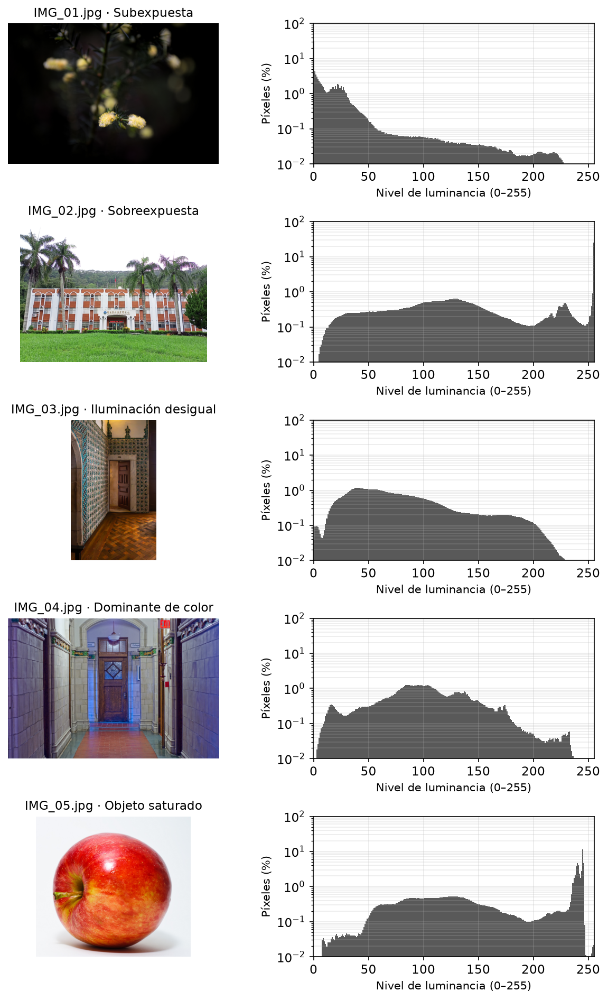

In [4]:
hists = [histograma_porcentaje(luminancia(cv2.imread(str(ruta)))) for ruta in imagenes]
fig, axes = plt.subplots(5, 2, figsize=(8, 12.5), constrained_layout=True)
for i, (ruta, h) in enumerate(zip(imagenes, hists)):
    img = cv2.imread(str(ruta))
    axes[i, 0].imshow(cv2.cvtColor(miniatura(img), cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{ruta.name} · {FUENTES[ruta.name]['rol']}")
    axes[i, 0].set_axis_off()
    axes[i, 1].bar(np.arange(256), h, width=1.0, color="0.35")
    axes[i, 1].set_xlim(-0.5, 255.5)
    axes[i, 1].set_yscale("log")
    axes[i, 1].set_ylim(0.01, 100.0)
    axes[i, 1].set_xlabel("Nivel de luminancia (0–255)")
    axes[i, 1].set_ylabel("Píxeles (%)")
    axes[i, 1].grid(alpha=0.25, which="both")
fig.savefig(OUT / "diagnostico_originales.png", bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(OUT / "diagnostico_originales.png")))

### Diagnóstico verbal y predicciones

Las predicciones se fijaron antes de ejecutar el barrido.
Las copio aquí tal cual para que quede constancia del orden de trabajo.

# Predicciones antes del barrido

Fecha: 26 de octubre de 2026. Escritas después de mirar el diagnóstico de las originales
y antes de calcular ninguna configuración procesada.

## IMG_01 (subexpuesta)

El 40,38 % de los píxeles tiene Y <= 2, la entropía es 4,98 bits y la desviación típica
32,8. La información está apelotonada en la zona oscura y no hay nada quemado. Espero que
gamma con g=0,6 sea la ganadora: debería liberar sombras sin llevar demasiados píxeles al
blanco. Gamma 0,45 también puede funcionar, pero me da miedo que aplane el fondo y baje la
entropía al juntar los grises.

## IMG_02 (sobreexpuesta)

Tiene un 26,36 % de píxeles en 253 o más, con una entropía de 6,63 bits y un rango de 238
niveles. Es una imagen con luces claramente quemadas, así que ninguna operación puntual
puede recuperar el detalle perdido. Espero que el criterio de respaldo acabe eligiendo una
configuración que no empeore aún más el blanco, probablemente gamma 2,2 o un CLAHE suave
con clip=1,0. No me sorprendería que la mejora frente a la original fuese nula.

## IMG_03 (iluminación desigual)

El rango entre percentiles es 192, la entropía 7,37 bits y la desviación 46,4, con solo un
0,23 % de píxeles en negro. Hay una ventana muy luminosa y una habitación en sombra en el
mismo encuadre. Aquí espero que CLAHE con clip=2,0 y bloques de 8×8 gane al estiramiento
global, porque necesita tratar de forma distinta las dos zonas. La dominante cálida de la
escena (medias RGB 98,4 / 74,6 / 53,5) no la corregirá un procesado sobre Y, y eso no me
preocupa para este ejercicio.

## IMG_04 (dominante de color)

La media del canal B (118,5) supera a la de R (104,4) y a la de G (96,9): la escena tira a
azul. La entropía es 7,32 bits y el rango 198, así que el histograma ya ocupa bastante. No
espero que el procesado arregle la dominante, porque trabajo solo sobre luminancia.
Predicción: CLAHE con clip=2,0 y bloques de 8×8 mejorará algo el contraste local, o quizá
HE si el histograma es suficientemente continuo.

## IMG_05 (objeto saturado)

El rango es 210, la entropía 6,73 bits y solo un 0,05 % de píxeles está quemado. La manzana
llena el encuadre y el fondo gris está bien separado. Es la imagen con menos margen de
mejora. Espero que gane gamma 1,0, que a efectos prácticos es la original, o un estiramiento
suave p=1–99. Si gana una operación más agresiva, miraré si el criterio está premiando el
rango a costa de inventar contraste en el fondo.

### Criterio de selección

El criterio se declaró y se guardó antes de generar `outputs/resultados_u1.csv`.

# Criterio de selección (fijado antes de ejecutar el barrido)

Fecha de fijación: 26 de octubre de 2026, antes de generar `outputs/resultados_u1.csv`.

## Por imagen

Entre las configuraciones procesadas que cumplan a la vez `sat_bajo <= 1,00 %` y
`sat_alto <= 1,00 %`, se elige la de mayor `rango_p1_p99`. Si hay empate, gana la de
mayor `entropia`; si el empate persiste, la configuración más sencilla según el orden
`gamma`, `estiramiento`, `he`, `clahe` y, dentro de cada operación, el orden en que
aparecen sus parámetros en el barrido.

La fila `original` no compite. Se conserva como línea base y se compara con la ganadora
para decidir si el procesado mejora de verdad. Si ninguna configuración procesada mejora
a la original, se dirá con las cifras delante.

Si ninguna configuración procesada cumple las dos restricciones para una imagen, se elige
la que minimice `max(sat_bajo, sat_alto)`. El desempate es mayor `rango_p1_p99`, después
mayor `entropia` y, por último, el orden de sencillez anterior. Esta regla se aplica tal
cual, sin retocarla después de ver los resultados.

## Para el lote

La configuración única del contrato será la que cumpla las dos restricciones en más
imágenes de las cinco. El desempate es el mayor rango medio de `rango_p1_p99` entre las
cinco imágenes, después la mayor entropía media y, por último, el orden de sencillez.
La fila `original` tampoco compite en el lote: el contrato debe describir un procesado
aplicable, no la ausencia de procesado.

## Tratamiento de gamma = 1,0

`gamma` con `g=1.0` es una operación procesada a efectos del barrido, pero su efecto es
prácticamente el de la original salvo el redondeo de la ida y vuelta de color. Puede
ganar por el criterio si sus métricas son las mejores; si eso ocurre, se comentará que
la ganancia procede del redondeo y no de un realce real.

## Ejercicio 2. Barrido sistemático

In [5]:
def reconstruir(img_bgr, Y2):
    """Sustituye Y conservando Cr y Cb, y vuelve a BGR."""
    ycc = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
    ycc[..., 0] = Y2.astype(np.uint8)
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2BGR)


def aplicar_gamma(img_bgr, gamma):
    """Gamma sobre Y: con gamma<1 aclara y con gamma>1 oscurece."""
    Y = luminancia(img_bgr)
    lut = np.array(
        [int(round(255.0 * (i / 255.0) ** gamma)) for i in range(256)],
        dtype=np.uint8,
    )
    return reconstruir(img_bgr, cv2.LUT(Y, lut))


def estirar(img_bgr, p_lo, p_hi):
    """Estiramiento lineal entre dos percentiles."""
    Y = luminancia(img_bgr)
    lo = float(np.percentile(Y, p_lo))
    hi = float(np.percentile(Y, p_hi))
    if hi <= lo:
        return img_bgr.copy()
    Y2 = np.clip((Y.astype(np.float64) - lo) / (hi - lo), 0.0, 1.0)
    return reconstruir(img_bgr, np.round(Y2 * 255.0).astype(np.uint8))


def ecualizar(img_bgr):
    """Ecualización global del canal Y."""
    return reconstruir(img_bgr, cv2.equalizeHist(luminancia(img_bgr)))


def clahe(img_bgr, clip, tile):
    """CLAHE sobre Y con el clip y la rejilla indicados."""
    operador = cv2.createCLAHE(
        clipLimit=float(clip), tileGridSize=(int(tile), int(tile))
    )
    return reconstruir(img_bgr, operador.apply(luminancia(img_bgr)))


CONFIGURACIONES = []
for g in [0.45, 0.6, 0.8, 1.0, 1.4, 1.8, 2.2]:
    CONFIGURACIONES.append({"operacion": "gamma", "parametros": f"g={g}", "gamma": g})
for p_lo, p_hi in [(0, 100), (1, 99), (2, 98), (5, 95)]:
    CONFIGURACIONES.append({
        "operacion": "estiramiento",
        "parametros": f"p={p_lo}-{p_hi}",
        "p_lo": p_lo,
        "p_hi": p_hi,
    })
CONFIGURACIONES.append({"operacion": "he", "parametros": "-"})
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        CONFIGURACIONES.append({
            "operacion": "clahe",
            "parametros": f"clip={clip:.1f};tile={tile}x{tile}",
            "clip": clip,
            "tile": tile,
        })
CONFIGURACIONES.append({"operacion": "original", "parametros": "-"})
assert len(CONFIGURACIONES) == 22


def aplicar_config(img_bgr, cfg):
    """Aplica una configuración del barrido."""
    op = cfg["operacion"]
    if op == "gamma":
        return aplicar_gamma(img_bgr, cfg["gamma"])
    if op == "estiramiento":
        return estirar(img_bgr, cfg["p_lo"], cfg["p_hi"])
    if op == "he":
        return ecualizar(img_bgr)
    if op == "clahe":
        return clahe(img_bgr, cfg["clip"], cfg["tile"])
    return img_bgr.copy()

In [6]:
COLUMNAS_CSV = [
    "imagen",
    "operacion",
    "parametros",
    "sat_bajo",
    "sat_alto",
    "rango_p1_p99",
    "entropia",
    "desv_tipica",
]
filas = []
t0 = time.time()
for ruta in imagenes:
    img = cv2.imread(str(ruta))
    for orden, cfg in enumerate(CONFIGURACIONES):
        salida = aplicar_config(img, cfg)
        d = diagnostico(salida)
        c = diagnostico_color(salida)
        filas.append({
            "imagen": ruta.name,
            "operacion": cfg["operacion"],
            "parametros": cfg["parametros"],
            "sat_bajo": d["sat_bajo"],
            "sat_alto": d["sat_alto"],
            "rango_p1_p99": d["rango_p1_p99"],
            "entropia": d["entropia"],
            "desv_tipica": d["desv_tipica"],
            "R": c["R"],
            "G": c["G"],
            "B": c["B"],
            "orden": orden,
        })
    print(f"{ruta.name}: {time.time() - t0:.1f} s acumulados")

res = pd.DataFrame(filas)
assert len(res) == 110
assert res.groupby("imagen").size().eq(22).all()
assert not res[COLUMNAS_CSV].isna().any().any()
assert res.duplicated(["imagen", "operacion", "parametros"]).sum() == 0

salida = pd.DataFrame({
    "imagen": res["imagen"],
    "operacion": res["operacion"],
    "parametros": res["parametros"],
    "sat_bajo": res["sat_bajo"].map(lambda x: f"{x:.2f}"),
    "sat_alto": res["sat_alto"].map(lambda x: f"{x:.2f}"),
    "rango_p1_p99": res["rango_p1_p99"].map(lambda x: f"{int(round(x))}"),
    "entropia": res["entropia"].map(lambda x: f"{x:.2f}"),
    "desv_tipica": res["desv_tipica"].map(lambda x: f"{x:.1f}"),
})
salida.to_csv(OUT / "resultados_u1.csv", index=False)

csv = pd.read_csv(OUT / "resultados_u1.csv")
assert list(csv.columns) == COLUMNAS_CSV
assert len(csv) == 110
assert csv.groupby("imagen").size().eq(22).all()
assert not csv.isna().any().any()
assert csv.duplicated(["imagen", "operacion", "parametros"]).sum() == 0
print("resultados_u1.csv:", csv.shape, "filas y columnas")

IMG_01.jpg: 26.4 s acumulados


IMG_02.jpg: 40.7 s acumulados


IMG_03.jpg: 68.8 s acumulados


IMG_04.jpg: 69.3 s acumulados


IMG_05.jpg: 74.7 s acumulados
resultados_u1.csv: (110, 8) filas y columnas


### Selección por código y comparación con las predicciones

In [7]:
mapa_orden = {
    f"{c['operacion']}|{c['parametros']}": k
    for k, c in enumerate(CONFIGURACIONES)
}
csv["orden"] = [
    mapa_orden[f"{op}|{par}"]
    for op, par in zip(csv["operacion"], csv["parametros"])
]

ganadoras = []
for ruta in imagenes:
    sub = csv[csv["imagen"] == ruta.name].copy()
    original = sub[sub["operacion"] == "original"].iloc[0]
    procesadas = sub[sub["operacion"] != "original"].copy()
    elegibles = procesadas[
        (procesadas["sat_bajo"] <= 1.0) & (procesadas["sat_alto"] <= 1.0)
    ]
    if len(elegibles) > 0:
        elegibles = elegibles.sort_values(
            ["rango_p1_p99", "entropia", "orden"],
            ascending=[False, False, True],
        )
        ganadora = elegibles.iloc[0]
        regla = "normal"
        n_elegibles = len(elegibles)
    else:
        procesadas["peor"] = np.maximum(procesadas["sat_bajo"], procesadas["sat_alto"])
        procesadas = procesadas.sort_values(
            ["peor", "rango_p1_p99", "entropia", "orden"],
            ascending=[True, False, False, True],
        )
        ganadora = procesadas.iloc[0]
        regla = "respaldo"
        n_elegibles = 0
    ganadoras.append({
        "imagen": ruta.name,
        "regla": regla,
        "n_elegibles": n_elegibles,
        "operacion": ganadora["operacion"],
        "parametros": ganadora["parametros"],
        "sat_bajo_original": original["sat_bajo"],
        "sat_alto_original": original["sat_alto"],
        "rango_original": original["rango_p1_p99"],
        "entropia_original": original["entropia"],
        "desv_original": original["desv_tipica"],
        "sat_bajo_ganadora": ganadora["sat_bajo"],
        "sat_alto_ganadora": ganadora["sat_alto"],
        "rango_ganadora": ganadora["rango_p1_p99"],
        "entropia_ganadora": ganadora["entropia"],
        "desv_ganadora": ganadora["desv_tipica"],
        "mejora_rango": ganadora["rango_p1_p99"] - original["rango_p1_p99"],
    })
ganadoras = pd.DataFrame(ganadoras)
ganadoras.to_csv(OUT / "ganadoras_por_imagen.csv", index=False, float_format="%.4f")
display(ganadoras[[
    "imagen", "regla", "operacion", "parametros", "rango_original",
    "rango_ganadora", "sat_bajo_original", "sat_bajo_ganadora",
    "sat_alto_original", "sat_alto_ganadora",
]])

,imagen,regla,operacion,parametros,rango_original,rango_ganadora,sat_bajo_original,sat_bajo_ganadora,sat_alto_original,sat_alto_ganadora
0,IMG_01.jpg,normal,clahe,clip=4.0;tile=8x8,178,215,40.38,0.01,0.00,0.00
1,IMG_02.jpg,respaldo,he,-,238,251,0.01,0.48,26.36,25.06
2,IMG_03.jpg,normal,he,-,192,246,0.23,0.70,0.00,0.17
3,IMG_04.jpg,normal,estiramiento,p=1-99,198,246,0.01,0.11,0.00,0.87
4,IMG_05.jpg,normal,clahe,clip=4.0;tile=4x4,210,233,0.00,0.04,0.05,0.08


In [8]:
procesadas = csv[csv["operacion"] != "original"].copy()
filas_lote = []
for (operacion, parametros), g in procesadas.groupby(["operacion", "parametros"]):
    cumple = (g["sat_bajo"] <= 1.0) & (g["sat_alto"] <= 1.0)
    filas_lote.append({
        "operacion": operacion,
        "parametros": parametros,
        "imagenes_que_cumplen": int(cumple.sum()),
        "imagenes_falla": ";".join(g.loc[~cumple, "imagen"].tolist()),
        "rango_medio": float(g["rango_p1_p99"].mean()),
        "entropia_media": float(g["entropia"].mean()),
        "orden": int(g["orden"].iloc[0]),
    })
lote = pd.DataFrame(filas_lote).sort_values(
    ["imagenes_que_cumplen", "rango_medio", "entropia_media", "orden"],
    ascending=[False, False, False, True],
)
lote_ganadora = lote.iloc[[0]].copy()
lote_ganadora.to_csv(OUT / "ganadora_lote.csv", index=False, float_format="%.4f")
display(lote.head(8))
print("Configuración del lote:", lote_ganadora.iloc[0]["operacion"],
      lote_ganadora.iloc[0]["parametros"])

,operacion,parametros,imagenes_que_cumplen,imagenes_falla,rango_medio,entropia_media,orden
7,clahe,clip=4.0;tile=4x4,4,IMG_02.jpg,234.6,7.182,18
8,clahe,clip=4.0;tile=8x8,4,IMG_02.jpg,230.8,7.160,19
6,clahe,clip=4.0;tile=16x16,4,IMG_02.jpg,227.4,7.080,20
5,clahe,clip=2.0;tile=8x8,4,IMG_02.jpg,225.0,7.008,16
3,clahe,clip=2.0;tile=16x16,4,IMG_02.jpg,222.2,6.938,17
4,clahe,clip=2.0;tile=4x4,3,IMG_01.jpg;IMG_02.jpg,229.0,7.058,15
1,clahe,clip=1.0;tile=4x4,3,IMG_01.jpg;IMG_02.jpg,219.0,6.878,12
2,clahe,clip=1.0;tile=8x8,3,IMG_01.jpg;IMG_02.jpg,216.0,6.848,13


Configuración del lote: clahe clip=4.0;tile=4x4


In [9]:
PREDICCIONES = {
    "IMG_01.jpg": ("gamma", "g=0.6"),
    "IMG_02.jpg": ("gamma", "g=2.2"),
    "IMG_03.jpg": ("clahe", "clip=2.0;tile=8x8"),
    "IMG_04.jpg": ("clahe", "clip=2.0;tile=8x8"),
    "IMG_05.jpg": ("gamma", "g=1.0"),
}
comparacion = ganadoras[["imagen", "operacion", "parametros", "rango_original", "rango_ganadora"]].copy()
comparacion["prediccion"] = comparacion["imagen"].map(
    lambda n: f"{PREDICCIONES[n][0]} {PREDICCIONES[n][1]}"
)
comparacion["acierto"] = comparacion.apply(
    lambda r: (r["operacion"], r["parametros"]) == PREDICCIONES[r["imagen"]],
    axis=1,
)
comparacion.to_csv(OUT / "comparacion_predicciones.csv", index=False)
display(comparacion)

,imagen,operacion,parametros,rango_original,rango_ganadora,prediccion,acierto
0,IMG_01.jpg,clahe,clip=4.0;tile=8x8,178,215,gamma g=0.6,False
1,IMG_02.jpg,he,-,238,251,gamma g=2.2,False
2,IMG_03.jpg,he,-,192,246,clahe clip=2.0;tile=8x8,False
3,IMG_04.jpg,estiramiento,p=1-99,198,246,clahe clip=2.0;tile=8x8,False
4,IMG_05.jpg,clahe,clip=4.0;tile=4x4,210,233,gamma g=1.0,False


## Figuras del barrido

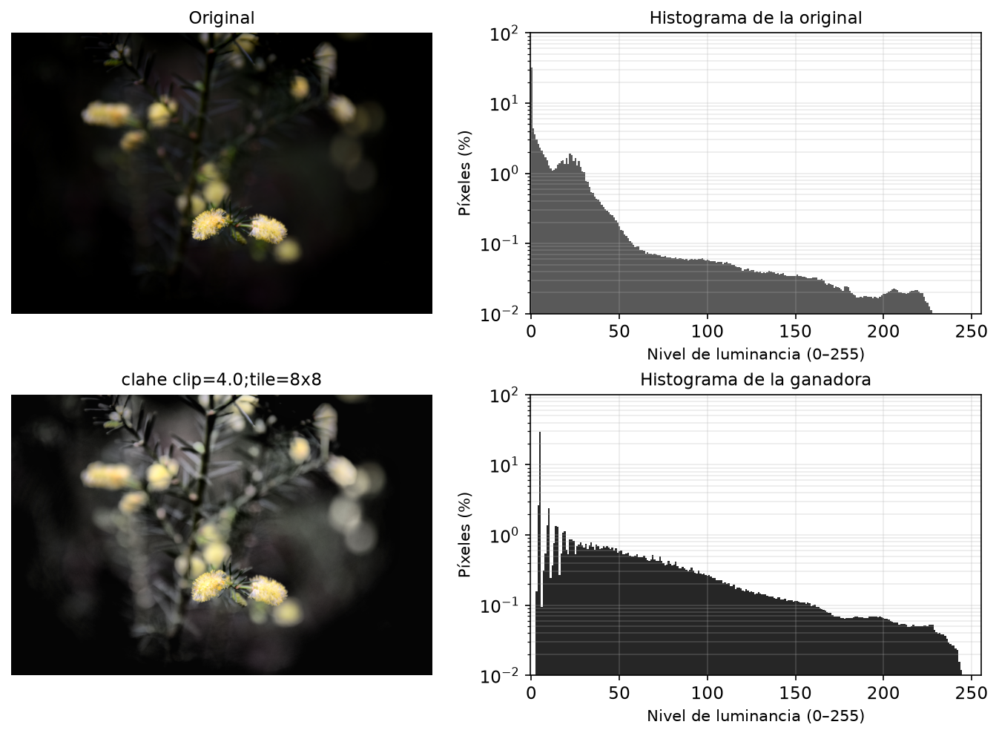

IMG_01.jpg: clahe clip=4.0;tile=8x8; rango 178 -> 215; sat_bajo 40.38 -> 0.01; sat_alto 0.00 -> 0.00


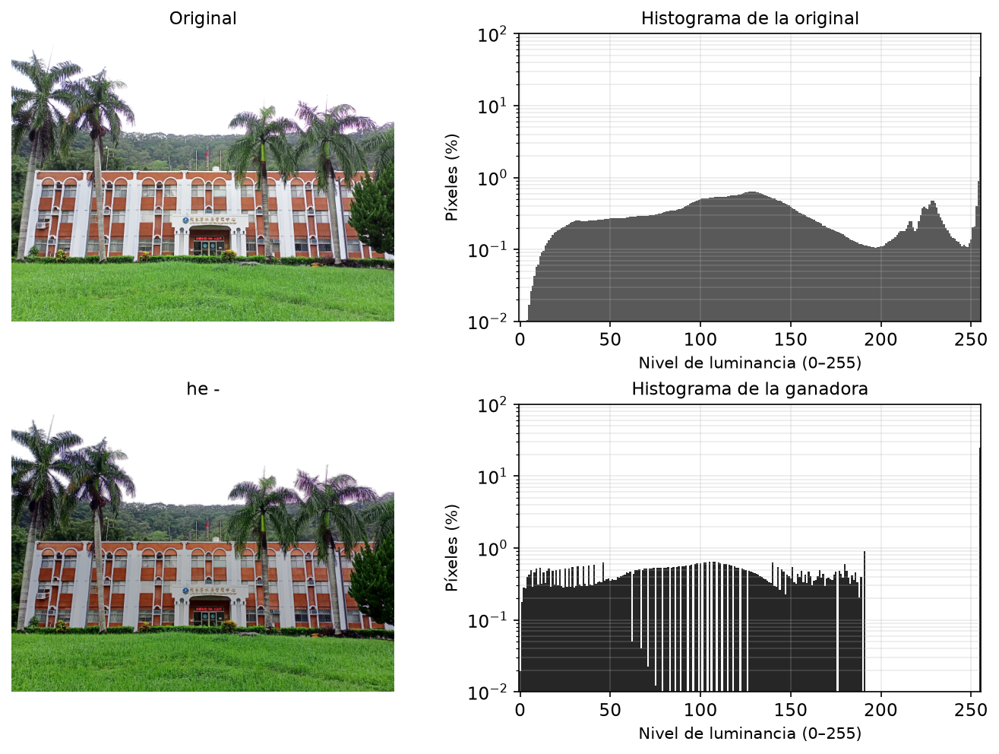

IMG_02.jpg: he -; rango 238 -> 251; sat_bajo 0.01 -> 0.48; sat_alto 26.36 -> 25.06


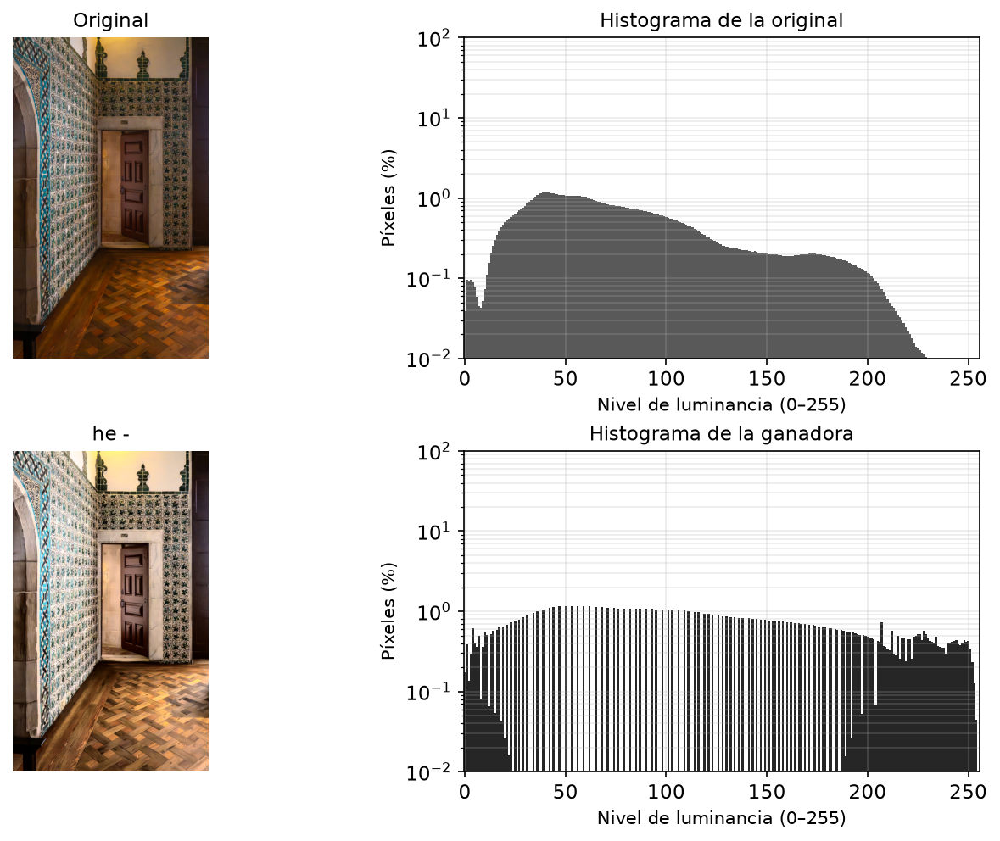

IMG_03.jpg: he -; rango 192 -> 246; sat_bajo 0.23 -> 0.70; sat_alto 0.00 -> 0.17


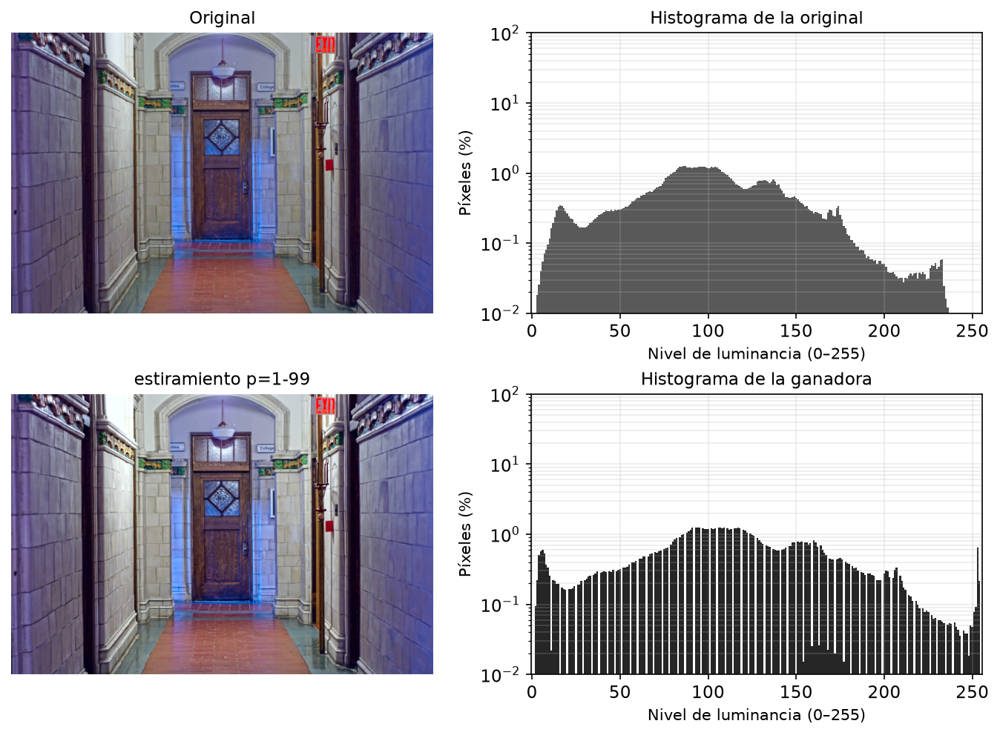

IMG_04.jpg: estiramiento p=1-99; rango 198 -> 246; sat_bajo 0.01 -> 0.11; sat_alto 0.00 -> 0.87


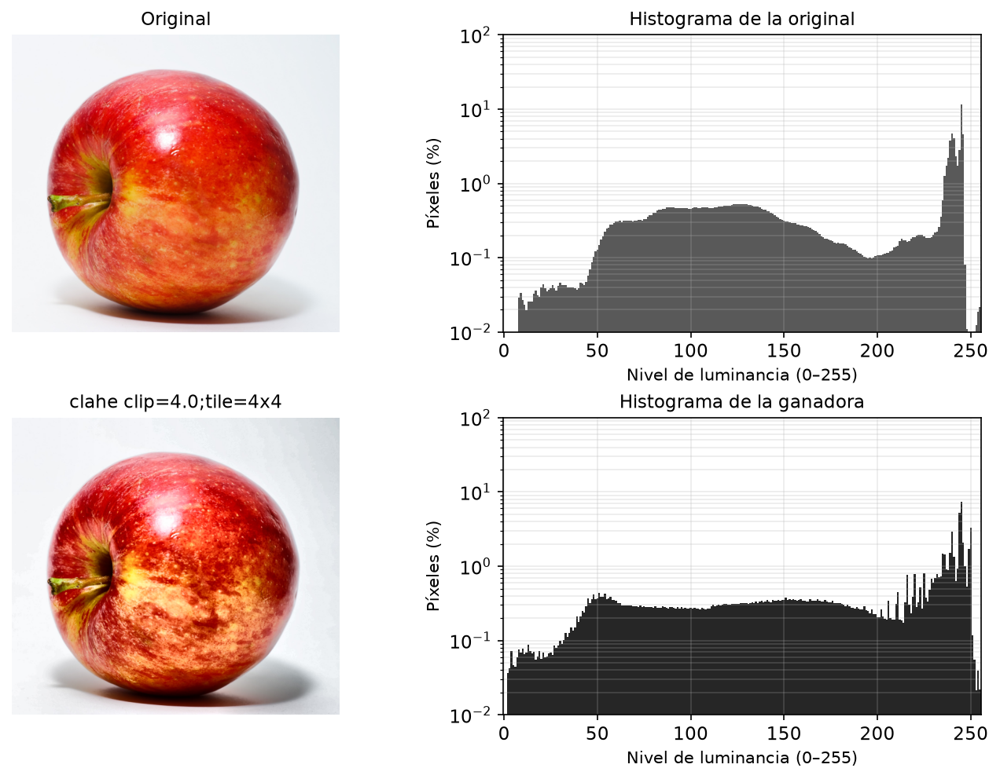

IMG_05.jpg: clahe clip=4.0;tile=4x4; rango 210 -> 233; sat_bajo 0.00 -> 0.04; sat_alto 0.05 -> 0.08


In [10]:
mapa_config = {
    f"{c['operacion']}|{c['parametros']}": c
    for c in CONFIGURACIONES
}
for i, ruta in enumerate(imagenes, start=1):
    img = cv2.imread(str(ruta))
    fila_ganadora = ganadoras[ganadoras["imagen"] == ruta.name].iloc[0]
    cfg = mapa_config[f"{fila_ganadora['operacion']}|{fila_ganadora['parametros']}"]
    img_ganadora = aplicar_config(img, cfg)
    fila_original = csv[
        (csv["imagen"] == ruta.name) & (csv["operacion"] == "original")
    ].iloc[0]
    fila_ganadora_csv = csv[
        (csv["imagen"] == ruta.name)
        & (csv["operacion"] == fila_ganadora["operacion"])
        & (csv["parametros"] == fila_ganadora["parametros"])
    ].iloc[0]

    Y_original = luminancia(img)
    Y_ganadora = luminancia(img_ganadora)
    h_original = histograma_porcentaje(Y_original)
    h_ganadora = histograma_porcentaje(Y_ganadora)

    fig, axes = plt.subplots(2, 2, figsize=(9, 6.5), constrained_layout=True)
    axes[0, 0].imshow(cv2.cvtColor(miniatura(img), cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title("Original")
    axes[0, 0].set_axis_off()
    axes[0, 1].bar(np.arange(256), h_original, width=1.0, color="0.35")
    axes[0, 1].set_xlim(-0.5, 255.5)
    axes[0, 1].set_yscale("log")
    axes[0, 1].set_ylim(0.01, 100.0)
    axes[0, 1].set_xlabel("Nivel de luminancia (0–255)")
    axes[0, 1].set_ylabel("Píxeles (%)")
    axes[0, 1].grid(alpha=0.25, which="both")
    axes[0, 1].set_title("Histograma de la original")
    axes[1, 0].imshow(cv2.cvtColor(miniatura(img_ganadora), cv2.COLOR_BGR2RGB))
    axes[1, 0].set_title(f"{fila_ganadora['operacion']} {fila_ganadora['parametros']}")
    axes[1, 0].set_axis_off()
    axes[1, 1].bar(np.arange(256), h_ganadora, width=1.0, color="0.15")
    axes[1, 1].set_xlim(-0.5, 255.5)
    axes[1, 1].set_yscale("log")
    axes[1, 1].set_ylim(0.01, 100.0)
    axes[1, 1].set_xlabel("Nivel de luminancia (0–255)")
    axes[1, 1].set_ylabel("Píxeles (%)")
    axes[1, 1].grid(alpha=0.25, which="both")
    axes[1, 1].set_title("Histograma de la ganadora")
    nombre = f"barrido_img{i:02d}.png"
    fig.savefig(OUT / nombre, bbox_inches="tight")
    plt.close(fig)
    display(IPImage(filename=str(OUT / nombre)))
    print(
        f"{ruta.name}: {fila_ganadora['operacion']} {fila_ganadora['parametros']}; "
        f"rango {fila_original['rango_p1_p99']:.0f} -> "
        f"{fila_ganadora_csv['rango_p1_p99']:.0f}; "
        f"sat_bajo {fila_original['sat_bajo']:.2f} -> "
        f"{fila_ganadora_csv['sat_bajo']:.2f}; "
        f"sat_alto {fila_original['sat_alto']:.2f} -> "
        f"{fila_ganadora_csv['sat_alto']:.2f}"
    )

## Comparación de la misma operación sobre Y y sobre cada canal RGB

,via,R,G,B,delta_R,delta_G,delta_B,distancia,B_menos_R
0,original,104.392156,96.893810,118.547269,0.000000,0.000000,0.000000,0.000000,14.155113
1,he_y,131.292105,123.900512,144.556015,26.899950,27.006703,26.008746,46.145684,13.263910
2,he_rgb,128.311535,128.044859,128.280769,23.919379,31.151049,9.733500,40.463139,-0.030766


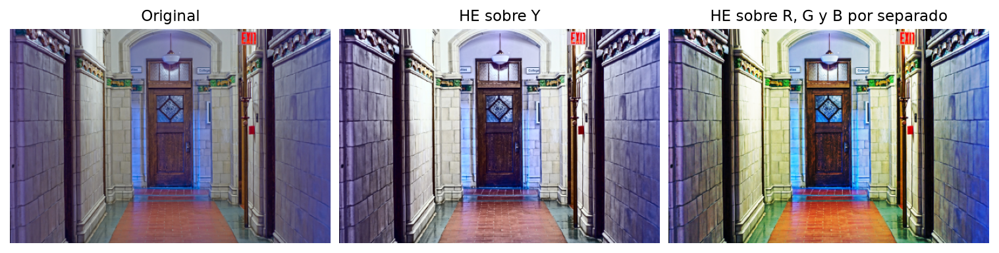

     via          R          G          B   delta_R   delta_G   delta_B  distancia  B_menos_R
original 104.392156  96.893810 118.547269  0.000000  0.000000  0.000000   0.000000  14.155113
    he_y 131.292105 123.900512 144.556015 26.899950 27.006703 26.008746  46.145684  13.263910
  he_rgb 128.311535 128.044859 128.280769 23.919379 31.151049  9.733500  40.463139  -0.030766


In [11]:
img_color = cv2.imread(str(DATA / "IMG_04.jpg"))
rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
rgb_he = rgb.copy()
for c in range(3):
    rgb_he[..., c] = cv2.equalizeHist(rgb_he[..., c])
he_y = ecualizar(img_color)
he_rgb = cv2.cvtColor(rgb_he, cv2.COLOR_RGB2BGR)

vias = [("original", img_color), ("he_y", he_y), ("he_rgb", he_rgb)]
medias_original = diagnostico_color(img_color)
filas_color = []
for via, im in vias:
    c = diagnostico_color(im)
    delta = {k: c[k] - medias_original[k] for k in ["R", "G", "B"]}
    distancia = float(np.sqrt(sum(v ** 2 for v in delta.values())))
    filas_color.append({
        "via": via,
        "R": c["R"],
        "G": c["G"],
        "B": c["B"],
        "delta_R": delta["R"],
        "delta_G": delta["G"],
        "delta_B": delta["B"],
        "distancia": distancia,
    })
color_df = pd.DataFrame(filas_color)
color_df["B_menos_R"] = color_df["B"] - color_df["R"]
color_df.to_csv(OUT / "comparacion_color.csv", index=False, float_format="%.2f")
display(color_df)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), constrained_layout=True)
titulos = ["Original", "HE sobre Y", "HE sobre R, G y B por separado"]
for ax, (_, im), titulo in zip(axes, vias, titulos):
    ax.imshow(cv2.cvtColor(miniatura(im, 440), cv2.COLOR_BGR2RGB))
    ax.set_title(titulo)
    ax.set_axis_off()
fig.savefig(OUT / "comparacion_luminancia_vs_rgb.png", bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(OUT / "comparacion_luminancia_vs_rgb.png")))
print(color_df.to_string(index=False))

## Ejercicio 3. Mosaico de Bayer y demosaico bilineal

In [12]:
def simular_bayer(rgb):
    """Mosaico 2D RGGB con un solo canal medido por posición."""
    alto, ancho = rgb.shape[:2]
    mosaico = np.zeros((alto, ancho), dtype=rgb.dtype)
    mosaico[0::2, 0::2] = rgb[0::2, 0::2, 0]
    mosaico[0::2, 1::2] = rgb[0::2, 1::2, 1]
    mosaico[1::2, 0::2] = rgb[1::2, 0::2, 1]
    mosaico[1::2, 1::2] = rgb[1::2, 1::2, 2]
    return mosaico


def mascaras_bayer(forma):
    """Máscaras booleanas de las posiciones medidas de R, G y B."""
    alto, ancho = forma
    m_r = np.zeros((alto, ancho), dtype=bool)
    m_g = np.zeros((alto, ancho), dtype=bool)
    m_b = np.zeros((alto, ancho), dtype=bool)
    m_r[0::2, 0::2] = True
    m_g[0::2, 1::2] = True
    m_g[1::2, 0::2] = True
    m_b[1::2, 1::2] = True
    return m_r, m_g, m_b


def demosaico_bilineal(mosaico):
    """Demosaico bilineal propio por convolución de canales dispersos."""
    m = mosaico.astype(np.float32)
    m_r, m_g, m_b = mascaras_bayer(mosaico.shape)
    k_g = np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=np.float32) / 4.0
    k_rb = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32) / 4.0
    canales = {}
    for nombre, mascara, kernel in [
        ("R", m_r, k_rb),
        ("G", m_g, k_g),
        ("B", m_b, k_rb),
    ]:
        disperso = np.where(mascara, m, 0.0).astype(np.float32)
        estimado = cv2.filter2D(
            disperso, -1, kernel, borderType=cv2.BORDER_REFLECT
        )
        estimado[mascara] = m[mascara]
        canales[nombre] = estimado
    reconstruida = np.stack([canales["R"], canales["G"], canales["B"]], axis=-1)
    return np.clip(np.rint(reconstruida), 0, 255).astype(np.uint8)


# Pruebas: constante y conservación exacta de los píxeles medidos.
constante = np.full((64, 64, 3), 128, dtype=np.uint8)
rec_constante = demosaico_bilineal(simular_bayer(constante))
assert np.array_equal(rec_constante[2:-2, 2:-2], constante[2:-2, 2:-2])
rng = np.random.default_rng(SEMILLA)
ruido = rng.integers(0, 256, size=(64, 64, 3), dtype=np.uint8)
rec_ruido = demosaico_bilineal(simular_bayer(ruido))
m_r, m_g, m_b = mascaras_bayer((64, 64))
for canal, mascara in [(0, m_r), (1, m_g), (2, m_b)]:
    assert np.array_equal(rec_ruido[..., canal][mascara], ruido[..., canal][mascara])
print("Pruebas de Bayer y demosaico: OK")

Pruebas de Bayer y demosaico: OK


In [13]:
img_bayer_bgr = cv2.imread(str(DATA / "IMG_03.jpg"))
rgb_bayer = cv2.cvtColor(img_bayer_bgr, cv2.COLOR_BGR2RGB)
alto, ancho = rgb_bayer.shape[:2]
alto_par = alto - alto % 2
ancho_par = ancho - ancho % 2
recorte = rgb_bayer[:alto_par, :ancho_par]
mosaico = simular_bayer(recorte)
reconstruida = demosaico_bilineal(mosaico)
assert np.array_equal(mosaico.shape, recorte.shape[:2])

m_r, m_g, m_b = mascaras_bayer(recorte.shape[:2])
fracciones = pd.DataFrame([
    {"canal": "R", "posiciones": int(m_r.sum()), "porcentaje": 100.0 * m_r.mean()},
    {"canal": "G", "posiciones": int(m_g.sum()), "porcentaje": 100.0 * m_g.mean()},
    {"canal": "B", "posiciones": int(m_b.sum()), "porcentaje": 100.0 * m_b.mean()},
])
assert abs(fracciones.loc[0, "porcentaje"] - 25.0) < 1e-9
assert abs(fracciones.loc[1, "porcentaje"] - 50.0) < 1e-9
assert abs(fracciones.loc[2, "porcentaje"] - 25.0) < 1e-9
fracciones.to_csv(OUT / "bayer_fracciones.csv", index=False, float_format="%.4f")
display(fracciones)

,canal,posiciones,porcentaje
0,R,5579280,25.0
1,G,11158560,50.0
2,B,5579280,25.0


In [14]:
diff = np.abs(recorte.astype(np.int16) - reconstruida.astype(np.int16))
mae_canales = {canal: float(diff[..., i].mean()) for i, canal in enumerate(["R", "G", "B"])}
error = diff.sum(axis=2).astype(np.uint16)

Y_bayer = cv2.cvtColor(recorte, cv2.COLOR_RGB2YCrCb)[..., 0]
bordes = cv2.Canny(Y_bayer, 100, 200)
bordes = cv2.dilate(bordes, np.ones((3, 3), dtype=np.uint8), iterations=1) > 0
mae_bordes = float(error[bordes].mean())
mae_resto = float(error[~bordes].mean())
cociente = mae_bordes / mae_resto
porcentaje_bordes = 100.0 * float(bordes.mean())

metricas = pd.DataFrame([
    {"imagen": "IMG_03.jpg", "metrica": "mae_R", "valor": mae_canales["R"]},
    {"imagen": "IMG_03.jpg", "metrica": "mae_G", "valor": mae_canales["G"]},
    {"imagen": "IMG_03.jpg", "metrica": "mae_B", "valor": mae_canales["B"]},
    {"imagen": "IMG_03.jpg", "metrica": "mae_total", "valor": float(diff.mean())},
    {"imagen": "IMG_03.jpg", "metrica": "mae_bordes", "valor": mae_bordes},
    {"imagen": "IMG_03.jpg", "metrica": "mae_resto", "valor": mae_resto},
    {"imagen": "IMG_03.jpg", "metrica": "cociente_bordes_resto", "valor": cociente},
    {"imagen": "IMG_03.jpg", "metrica": "porcentaje_bordes", "valor": porcentaje_bordes},
    {"imagen": "IMG_03.jpg", "metrica": "umbral_canny_bajo", "valor": 100},
    {"imagen": "IMG_03.jpg", "metrica": "umbral_canny_alto", "valor": 200},
    {"imagen": "IMG_03.jpg", "metrica": "dilatacion_px", "valor": 3},
    {"imagen": "IMG_03.jpg", "metrica": "lado_recorte", "valor": 900},
    {"imagen": "IMG_03.jpg", "metrica": "ancho_original", "valor": int(img_bayer_bgr.shape[1])},
    {"imagen": "IMG_03.jpg", "metrica": "alto_original", "valor": int(img_bayer_bgr.shape[0])},
    {"imagen": "IMG_03.jpg", "metrica": "ancho_recortado", "valor": int(recorte.shape[1])},
    {"imagen": "IMG_03.jpg", "metrica": "alto_recortado", "valor": int(recorte.shape[0])},
])
metricas.to_csv(OUT / "demosaico_metricas.csv", index=False, float_format="%.4f")
display(metricas)

,imagen,metrica,valor
0,IMG_03.jpg,mae_R,3.901098
1,IMG_03.jpg,mae_G,1.800903
2,IMG_03.jpg,mae_B,3.426916
3,IMG_03.jpg,mae_total,3.042972
4,IMG_03.jpg,mae_bordes,18.475975
5,IMG_03.jpg,mae_resto,6.929324
6,IMG_03.jpg,cociente_bordes_resto,2.666346
7,IMG_03.jpg,porcentaje_bordes,19.049618
8,IMG_03.jpg,umbral_canny_bajo,100.000000
9,IMG_03.jpg,umbral_canny_alto,200.000000


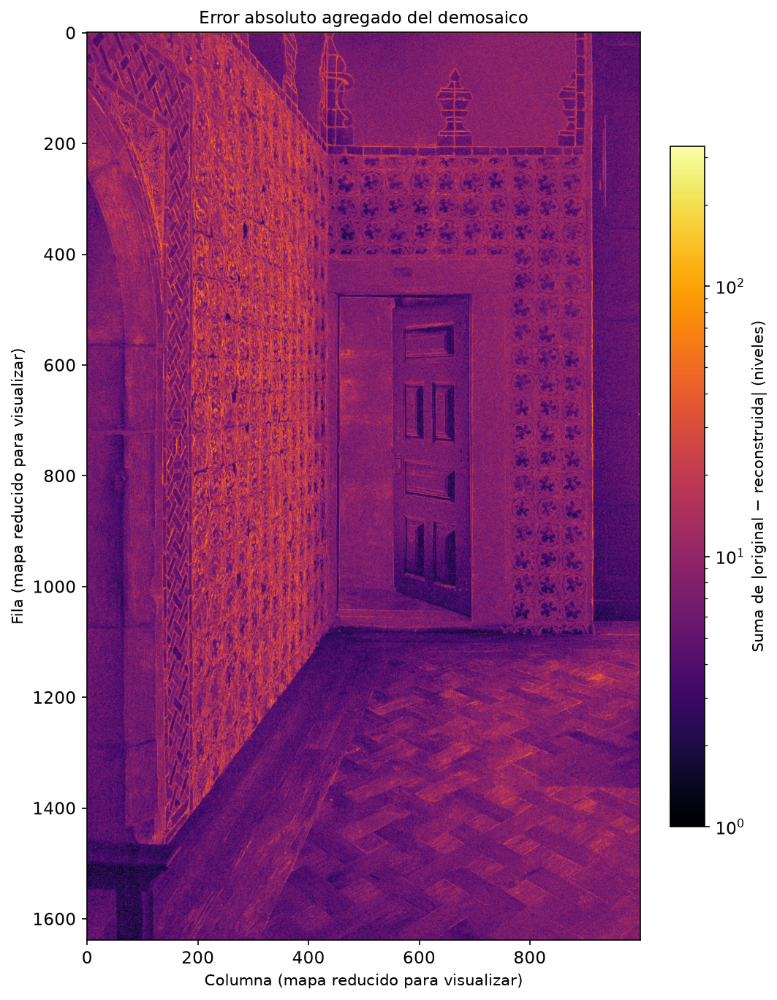

In [15]:
error_visible = cv2.resize(
    error, (1000, int(1000 * error.shape[0] / error.shape[1])),
    interpolation=cv2.INTER_AREA,
)
fig, ax = plt.subplots(figsize=(7, 9), constrained_layout=True)
im = ax.imshow(
    error_visible,
    cmap="inferno",
    norm=LogNorm(vmin=1.0, vmax=float(error.max())),
)
ax.set_title("Error absoluto agregado del demosaico")
ax.set_xlabel("Columna (mapa reducido para visualizar)")
ax.set_ylabel("Fila (mapa reducido para visualizar)")
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.set_label("Suma de |original − reconstruida| (niveles)")
fig.savefig(OUT / "error_demosaico.png", bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(OUT / "error_demosaico.png")))

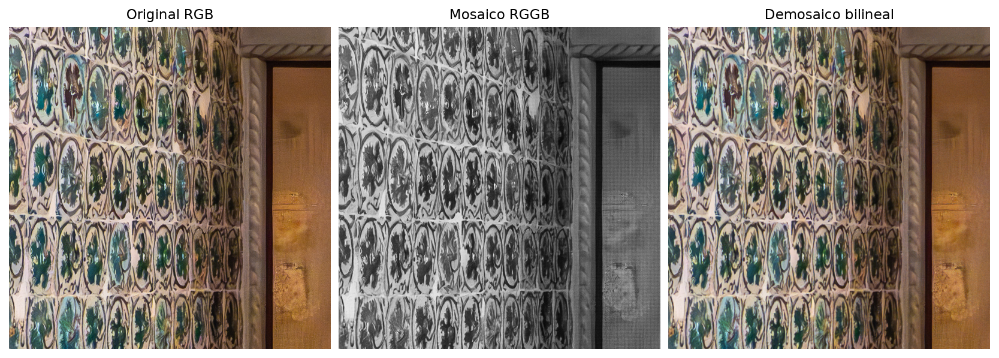

MAE por canal: R 3.90, G 1.80, B 3.43; bordes 18.48 frente a resto 6.93; cociente 2.67


In [16]:
lado = 900
x0 = min(950, recorte.shape[1] - lado)
y0 = min(1650, recorte.shape[0] - lado)
crop_original = recorte[y0:y0 + lado, x0:x0 + lado]
crop_mosaico = mosaico[y0:y0 + lado, x0:x0 + lado]
crop_recon = reconstruida[y0:y0 + lado, x0:x0 + lado]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), constrained_layout=True)
axes[0].imshow(crop_original)
axes[0].set_title("Original RGB")
axes[1].imshow(crop_mosaico, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Mosaico RGGB")
axes[2].imshow(crop_recon)
axes[2].set_title("Demosaico bilineal")
for ax in axes:
    ax.set_axis_off()
fig.savefig(OUT / "demosaico_visual.png", bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(OUT / "demosaico_visual.png")))
print(
    f"MAE por canal: R {mae_canales['R']:.2f}, G {mae_canales['G']:.2f}, "
    f"B {mae_canales['B']:.2f}; bordes {mae_bordes:.2f} frente a resto "
    f"{mae_resto:.2f}; cociente {cociente:.2f}"
)

## Ejercicio 4. Robustez de la segmentación HSV

El objeto de IMG_05 es una manzana roja. En OpenCV el tono va de 0 a 179 y el rojo cae en
la costura de la escala, así que uso dos ventanas: H <= 20 y H >= 160. Exijo S >= 70 para
descartar el fondo gris y V >= 30 para no perder la sombra de la manzana. Después me
quedo con la componente conexa mayor para eliminar motas de JPEG. Estos valores quedan
congelados a partir de este momento.

,hue_alto,hue_bajo,sat_min,val_min,componente_mayor,area_pixeles,area_porcentaje
0,20,160,70,30,1,2615612,49.348786


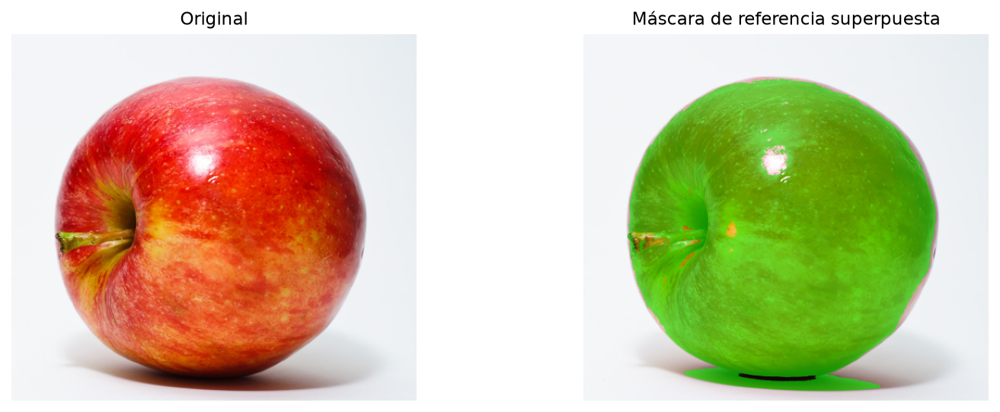

In [17]:
HUE_ALTO = 20
HUE_BAJO = 160
SAT_MIN = 70
VAL_MIN = 30


def segmentar_hsv(img_bgr):
    """Máscara binaria del objeto con los rangos HSV congelados."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    H, S, V = cv2.split(hsv)
    mascara = (
        ((H <= HUE_ALTO) | (H >= HUE_BAJO))
        & (S >= SAT_MIN)
        & (V >= VAL_MIN)
    ).astype(np.uint8)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(mascara)
    if n > 1:
        mayor = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        mascara = (etiquetas == mayor).astype(np.uint8)
    return mascara


def iou(mascara_a, mascara_b):
    """Intersección sobre unión de dos máscaras binarias."""
    a = mascara_a.astype(bool)
    b = mascara_b.astype(bool)
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union > 0 else 0.0


img_objeto = cv2.imread(str(DATA / "IMG_05.jpg"))
mascara_referencia = segmentar_hsv(img_objeto)
assert iou(mascara_referencia, mascara_referencia) == 1.0
cv2.imwrite(str(OUT / "mascara_referencia.png"), (mascara_referencia * 255).astype(np.uint8))
overlay = img_objeto.copy()
seleccion = mascara_referencia.astype(bool)
overlay[seleccion] = (
    0.45 * overlay[seleccion] + 0.55 * np.array([0, 255, 0])
).astype(np.uint8)
cv2.imwrite(str(OUT / "mascara_referencia_overlay.png"), overlay)

hsv_ref = pd.DataFrame([{
    "hue_alto": HUE_ALTO,
    "hue_bajo": HUE_BAJO,
    "sat_min": SAT_MIN,
    "val_min": VAL_MIN,
    "componente_mayor": 1,
    "area_pixeles": int(mascara_referencia.sum()),
    "area_porcentaje": 100.0 * float(mascara_referencia.mean()),
}])
hsv_ref.to_csv(OUT / "hsv_referencia.csv", index=False, float_format="%.4f")
display(hsv_ref)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].imshow(cv2.cvtColor(miniatura(img_objeto, 500), cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[0].set_axis_off()
axes[1].imshow(cv2.cvtColor(miniatura(overlay, 500), cv2.COLOR_BGR2RGB))
axes[1].set_title("Máscara de referencia superpuesta")
axes[1].set_axis_off()
fig.savefig(OUT / "mascara_referencia_visual.png", bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(OUT / "mascara_referencia_visual.png")))

In [18]:
def perturbar_gamma(img_bgr, gamma):
    """Perturbación de iluminación sobre Y; gamma=1.0 es el control exacto."""
    if gamma == 1.0:
        return img_bgr.copy()
    return aplicar_gamma(img_bgr, gamma)


fila_objeto = ganadoras[ganadoras["imagen"] == "IMG_05.jpg"].iloc[0]
cfg_objeto = mapa_config[f"{fila_objeto['operacion']}|{fila_objeto['parametros']}"]
gammas = [0.5, 0.7, 1.0, 1.4, 2.0]
filas_robustez = []
for gamma in gammas:
    perturbada = perturbar_gamma(img_objeto, gamma)
    mascara_sin = segmentar_hsv(perturbada)
    iou_sin = iou(mascara_referencia, mascara_sin)
    normalizada = aplicar_config(perturbada, cfg_objeto)
    mascara_con = segmentar_hsv(normalizada)
    iou_con = iou(mascara_referencia, mascara_con)
    filas_robustez.append({
        "gamma": gamma,
        "condicion": "sin_normalizacion",
        "iou": iou_sin,
        "pixeles_mascara": int(mascara_sin.sum()),
    })
    filas_robustez.append({
        "gamma": gamma,
        "condicion": "con_normalizacion",
        "iou": iou_con,
        "pixeles_mascara": int(mascara_con.sum()),
    })

robustez = pd.DataFrame(filas_robustez)
assert len(robustez) == 10
control = robustez[
    (robustez["gamma"] == 1.0) & (robustez["condicion"] == "sin_normalizacion")
].iloc[0]
assert abs(control["iou"] - 1.0) < 1e-12
robustez.to_csv(OUT / "robustez_hsv.csv", index=False, float_format="%.6f")
display(robustez)

,gamma,condicion,iou,pixeles_mascara
0,0.5,sin_normalizacion,0.943947,2472826
1,0.5,con_normalizacion,0.955578,2500752
2,0.7,sin_normalizacion,0.983965,2595628
3,0.7,con_normalizacion,0.965300,2530349
4,1.0,sin_normalizacion,1.000000,2615612
5,1.0,con_normalizacion,0.970960,2551913
6,1.4,sin_normalizacion,0.984250,2633942
7,1.4,con_normalizacion,0.975812,2578785
8,2.0,sin_normalizacion,0.967837,2652818
9,2.0,con_normalizacion,0.975558,2607319


In [19]:
resumen_filas = []
for condicion, g in robustez.groupby("condicion"):
    peor = g.loc[g["iou"].idxmin()]
    resumen_filas.append({
        "condicion": condicion,
        "iou_media": float(g["iou"].mean()),
        "iou_peor": float(g["iou"].min()),
        "gamma_peor": float(peor["gamma"]),
        "iou_control": float(g.loc[g["gamma"] == 1.0, "iou"].iloc[0]),
    })
resumen = pd.DataFrame(resumen_filas)
media_sin = resumen.loc[resumen["condicion"] == "sin_normalizacion", "iou_media"].iloc[0]
media_con = resumen.loc[resumen["condicion"] == "con_normalizacion", "iou_media"].iloc[0]
resumen["diferencia_media"] = resumen["iou_media"] - media_sin
resumen.to_csv(OUT / "resumen_robustez.csv", index=False, float_format="%.6f")
display(resumen)

,condicion,iou_media,iou_peor,gamma_peor,iou_control,diferencia_media
0,con_normalizacion,0.968642,0.955578,0.5,0.97096,-0.007358
1,sin_normalizacion,0.976000,0.943947,0.5,1.00000,0.000000


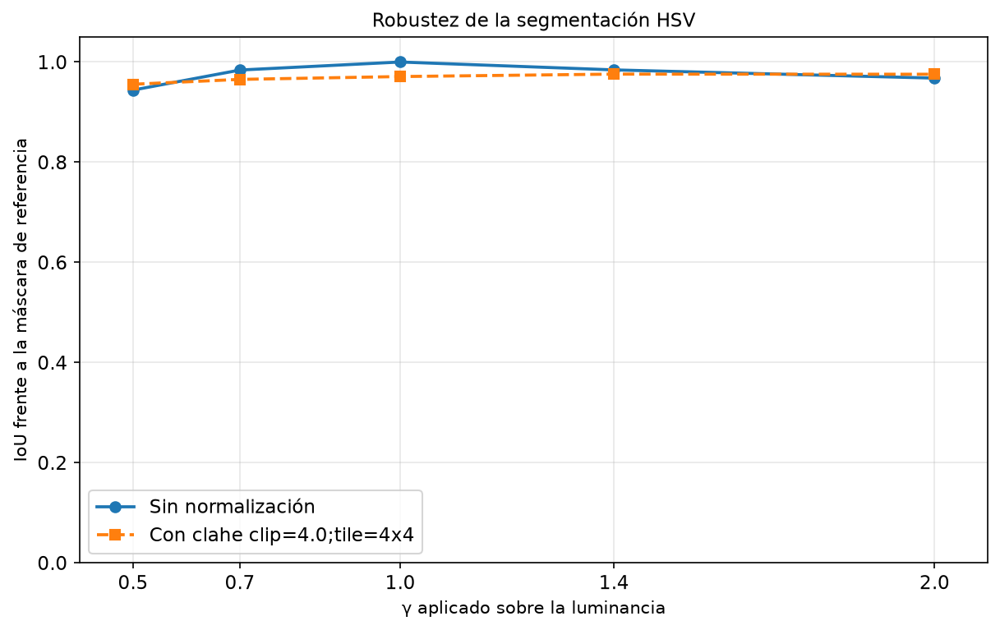

        condicion  iou_media  iou_peor  gamma_peor  iou_control  diferencia_media
con_normalizacion   0.968642  0.955578         0.5      0.97096         -0.007358
sin_normalizacion   0.976000  0.943947         0.5      1.00000          0.000000


In [20]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for condicion, estilo, etiqueta in [
    ("sin_normalizacion", "o-", "Sin normalización"),
    ("con_normalizacion", "s--", f"Con {fila_objeto['operacion']} {fila_objeto['parametros']}"),
]:
    g = robustez[robustez["condicion"] == condicion]
    ax.plot(g["gamma"], g["iou"], estilo, label=etiqueta, linewidth=1.8)
ax.set_xlabel("γ aplicado sobre la luminancia")
ax.set_ylabel("IoU frente a la máscara de referencia")
ax.set_xlim(0.4, 2.1)
ax.set_ylim(0.0, 1.05)
ax.set_xticks(gammas)
ax.grid(alpha=0.3)
ax.legend()
ax.set_title("Robustez de la segmentación HSV")
fig.savefig(OUT / "robustez_hsv.png", bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=str(OUT / "robustez_hsv.png")))
print(resumen.to_string(index=False))

## Ejercicio 5. Contrato de preprocesado

La regla de lote elige `clahe` con `clip=4.0` y `tile=4x4`; coincide con la ganadora de
IMG_05, así que la intervención del Ejercicio 4 y el contrato son la misma operación.

In [21]:
# Fila del contrato: IMG_05.jpg, clahe, clip=4.0;tile=4x4 (ganadora_lote.csv).
OPERACION_CONTRATO = "clahe"
PARAMETROS_CONTRATO = "clip=4.0;tile=4x4"
CLIP_CONTRATO = 4.0
TILE_CONTRATO = 4

fila_lote = lote_ganadora.iloc[0]
assert OPERACION_CONTRATO == fila_lote["operacion"]
assert PARAMETROS_CONTRATO == fila_lote["parametros"]


def preprocesar(img_bgr):
    """Contrato del lote: CLAHE con clip 4,0 y rejilla 4x4 sobre Y, entrada y salida BGR."""
    return clahe(img_bgr, CLIP_CONTRATO, TILE_CONTRATO)


filas_pre = []
for ruta in imagenes:
    img = cv2.imread(str(ruta))
    salida = preprocesar(img)
    assert salida.dtype == np.uint8
    assert salida.shape == img.shape
    d = diagnostico(salida)
    c = diagnostico_color(salida)
    fila = csv[
        (csv["imagen"] == ruta.name)
        & (csv["operacion"] == OPERACION_CONTRATO)
        & (csv["parametros"] == PARAMETROS_CONTRATO)
    ].iloc[0]
    assert f"{d['sat_bajo']:.2f}" == f"{fila['sat_bajo']:.2f}"
    assert f"{d['sat_alto']:.2f}" == f"{fila['sat_alto']:.2f}"
    assert int(round(d["rango_p1_p99"])) == int(round(fila["rango_p1_p99"]))
    assert f"{d['entropia']:.2f}" == f"{fila['entropia']:.2f}"
    assert f"{d['desv_tipica']:.1f}" == f"{fila['desv_tipica']:.1f}"
    original = diag[diag["imagen"] == ruta.name].iloc[0]
    filas_pre.append({
        "imagen": ruta.name,
        "sat_bajo": round(d["sat_bajo"], 2),
        "sat_alto": round(d["sat_alto"], 2),
        "rango_p1_p99": int(round(d["rango_p1_p99"])),
        "entropia": round(d["entropia"], 2),
        "desv_tipica": round(d["desv_tipica"], 1),
        "sat_bajo_original": original["sat_bajo"],
        "sat_alto_original": original["sat_alto"],
        "rango_original": original["rango_p1_p99"],
        "R": round(c["R"], 1),
        "G": round(c["G"], 1),
        "B": round(c["B"], 1),
        "B_menos_R": round(c["B"] - c["R"], 1),
    })
pre = pd.DataFrame(filas_pre)
pre.to_csv(OUT / "diagnostico_preprocesado.csv", index=False)
umbrales = pd.DataFrame([
    {"metrica": "sat_alto", "umbral": 5.0},
    {"metrica": "rango_p1_p99", "umbral": 200},
])
umbrales.to_csv(OUT / "umbrales_contrato.csv", index=False)
display(pre)
display(umbrales)
print("El contrato reproduce exactamente su fila del CSV en las cinco imágenes.")

,imagen,sat_bajo,sat_alto,rango_p1_p99,entropia,desv_tipica,sat_bajo_original,sat_alto_original,rango_original,R,G,B,B_menos_R
0,IMG_01.jpg,0.00,0.00,212,6.01,53.2,40.38,0.00,178,50.6,49.4,44.6,-6.0
1,IMG_02.jpg,0.22,25.18,249,6.78,82.5,0.01,26.36,238,156.4,165.6,143.4,-13.0
2,IMG_03.jpg,0.22,0.05,240,7.94,67.5,0.23,0.00,192,140.4,117.7,96.7,-43.7
3,IMG_04.jpg,0.04,0.08,239,7.92,65.0,0.01,0.00,198,129.2,121.7,142.9,13.7
4,IMG_05.jpg,0.04,0.08,233,7.26,71.9,0.00,0.05,210,216.2,155.6,142.1,-74.1


,metrica,umbral
0,sat_alto,5.0
1,rango_p1_p99,200.0


El contrato reproduce exactamente su fila del CSV en las cinco imágenes.


In [22]:
auditoria = pd.DataFrame([{
    "n_imagenes": 5,
    "n_configuraciones": 22,
    "n_filas_resultados": 110,
    "n_filas_robustez": 10,
    "n_gammas": 5,
    "n_gammas_barrido": 7,
    "n_estiramientos": 4,
    "n_clahe": 9,
    "semilla": 42,
}])
auditoria.to_csv(OUT / "resumen_auditoria.csv", index=False)
criterio_csv = pd.DataFrame([{"sat_bajo_max": 1.0, "sat_alto_max": 1.0}])
criterio_csv.to_csv(OUT / "criterio_aplicado.csv", index=False)
constantes = pd.DataFrame([
    {"constante": "niveles", "valor": "256"},
    {"constante": "valor_max", "valor": "255"},
    {"constante": "kernel_g", "valor": "0,1,0;1,4,1;0,1,0"},
    {"constante": "kernel_rb", "valor": "1,2,1;2,4,2;1,2,1"},
])
constantes.to_csv(OUT / "constantes.csv", index=False)

archivos_esperados = [
    "resultados_u1.csv",
    "resumen_auditoria.csv",
    "criterio_aplicado.csv",
    "constantes.csv",
    "robustez_hsv.csv",
    "diagnostico_originales.csv",
    "ganadoras_por_imagen.csv",
    "ganadora_lote.csv",
    "comparacion_color.csv",
    "bayer_fracciones.csv",
    "demosaico_metricas.csv",
    "hsv_referencia.csv",
    "resumen_robustez.csv",
    "diagnostico_preprocesado.csv",
    "umbrales_contrato.csv",
    "diagnostico_originales.png",
    "comparacion_luminancia_vs_rgb.png",
    "error_demosaico.png",
    "demosaico_visual.png",
    "mascara_referencia.png",
    "mascara_referencia_visual.png",
    "robustez_hsv.png",
]
archivos_esperados += [f"barrido_img{i:02d}.png" for i in range(1, 6)]
faltan = [n for n in archivos_esperados if not (OUT / n).exists()]
assert not faltan, f"Faltan salidas: {faltan}"
print("Salidas generadas:", len(archivos_esperados), "archivos")

Salidas generadas: 27 archivos
